# 03. Zmienność krocząca, średnie i rozkład zwrotów

Dane od 15.06.2022 służą do wyznaczenia średnich i zmienności kroczącej od 1.01.2023. Wskaźniki wymagają pełnych okien kalendarzowych. Po luce EMA zaczyna się od SMA z pierwszego pełnego okna po wznowieniu danych. Histogram obejmuje zwroty między kolejnymi dniami wybranego okresu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from market_data import daily_price_ratios, download


def ema(prices, window):
    calendar = prices.sort_index().asfreq("D").astype(float)
    result = pd.Series(np.nan, index=calendar.index, dtype=float)
    segments = calendar.isna().cumsum()
    for _, segment in calendar.dropna().groupby(segments):
        if len(segment) < window:
            continue
        seeded = segment.iloc[window - 1:].copy()
        seeded.iloc[0] = segment.iloc[:window].mean()
        result.loc[seeded.index] = seeded.ewm(span=window, adjust=False).mean()
    return result


def rolling_volatility(prices, window=30):
    calendar = prices.sort_index().asfreq("D")
    log_returns = np.log(daily_price_ratios(calendar))
    return log_returns.rolling(window).std(ddof=1) * np.sqrt(365)


def freedman_diaconis_bins(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    if len(series) < 2 or iqr <= 0:
        return 20, iqr, np.nan
    width = 2.0 * iqr * len(series) ** (-1.0 / 3.0)
    raw_bins = int(np.ceil((series.max() - series.min()) / width))
    return int(np.clip(raw_bins, 20, 100)), iqr, width

In [2]:
# Kontrola na danych testowych
dates = pd.date_range("2023-01-01", periods=5, freq="D", tz="UTC")
test_prices = pd.Series([100, 110, 99, 108.9, 102.366], index=dates)
test_ema = ema(test_prices, 3).dropna()
np.testing.assert_allclose(test_ema.values, [103.0, 105.95, 104.158], atol=1e-9)

test_vol = rolling_volatility(test_prices, window=3).dropna()
np.testing.assert_allclose(test_vol.values, [2.2134502273, 2.0168643809], atol=1e-9)

test_log = np.log(test_prices / test_prices.shift()).dropna()
_, iqr_t, h_t = freedman_diaconis_bins(test_log)
np.testing.assert_allclose([iqr_t, h_t], [0.1680568615, 0.2117383774], atol=1e-9)
gap_dates = pd.date_range("2023-01-01", periods=7, freq="D", tz="UTC")
gap_prices = pd.Series([100, 110, 121, 133.1, 146.41, 161.051, 177.1561], index=gap_dates).drop(gap_dates[3])
gap_sma = gap_prices.asfreq("D").rolling(3).mean()
gap_ema = ema(gap_prices, 3)
assert gap_sma.loc[gap_dates[3:6]].isna().all()
assert gap_ema.loc[gap_dates[3:6]].isna().all()
np.testing.assert_allclose(gap_ema.loc[gap_dates[6]], gap_sma.loc[gap_dates[6]])
assert rolling_volatility(gap_prices, 2).dropna().index.equals(gap_dates[[2, 6]])
assert freedman_diaconis_bins(pd.Series([0.0, 0.0]))[0] == 20
print("Obliczenia kontrolne dla EMA, zmienności kroczącej i reguły Freedmana-Diaconisa przeszły pomyślnie.")

Obliczenia kontrolne dla EMA, zmienności kroczącej i reguły Freedmana-Diaconisa przeszły pomyślnie.


In [3]:
bnb, checks = download("BNBUSDT")
print(f"BNBUSDT: ostatni dzień UTC {bnb.index.max().date()}, brakujących dni: {len(checks['missing_dates'])}")

close = bnb.close.asfreq("D")
period_close = close.loc["2023-01-01":]
windows = (20, 50, 200)
sma = {w: close.rolling(w).mean().loc["2023-01-01":] for w in windows}
ema_series = {w: ema(close, w).loc["2023-01-01":] for w in windows}
vol30 = rolling_volatility(close, 30).loc["2023-01-01":]
log_ret = np.log(daily_price_ratios(period_close)).dropna()
bins, iqr, h = freedman_diaconis_bins(log_ret)

if not period_close.empty:
    print(f"Ostatnie wartości na {period_close.index.max().date()}:")
    for w in windows:
        print(f"  SMA {w} = {sma[w].iloc[-1]:.2f}, EMA {w} = {ema_series[w].iloc[-1]:.2f}")
    print(f"  Zmienność 30-dniowa w skali roku = {vol30.iloc[-1]:.2%}, min = {vol30.min():.2%}, max = {vol30.max():.2%}")
if len(log_ret) >= 2:
    print(f"  Histogram: n = {len(log_ret)}, IQR = {iqr:.6f}, h = {h:.6f}, przedziały = {bins}")
else:
    print("  Brak co najmniej dwóch dziennych zwrotów do histogramu.")

BNBUSDT: ostatni dzień UTC 2026-11-15, brakujących dni: 0
Ostatnie wartości na 2026-11-15:
  SMA 20 = 686.21, EMA 20 = 675.38
  SMA 50 = 724.98, EMA 50 = 703.21
  SMA 200 = 658.48, EMA 200 = 689.81
  Zmienność 30-dniowa w skali roku = 51.69%, min = 19.94%, max = 107.61%
  Histogram: n = 1414, IQR = 0.024570, h = 0.004378, przedziały = 68


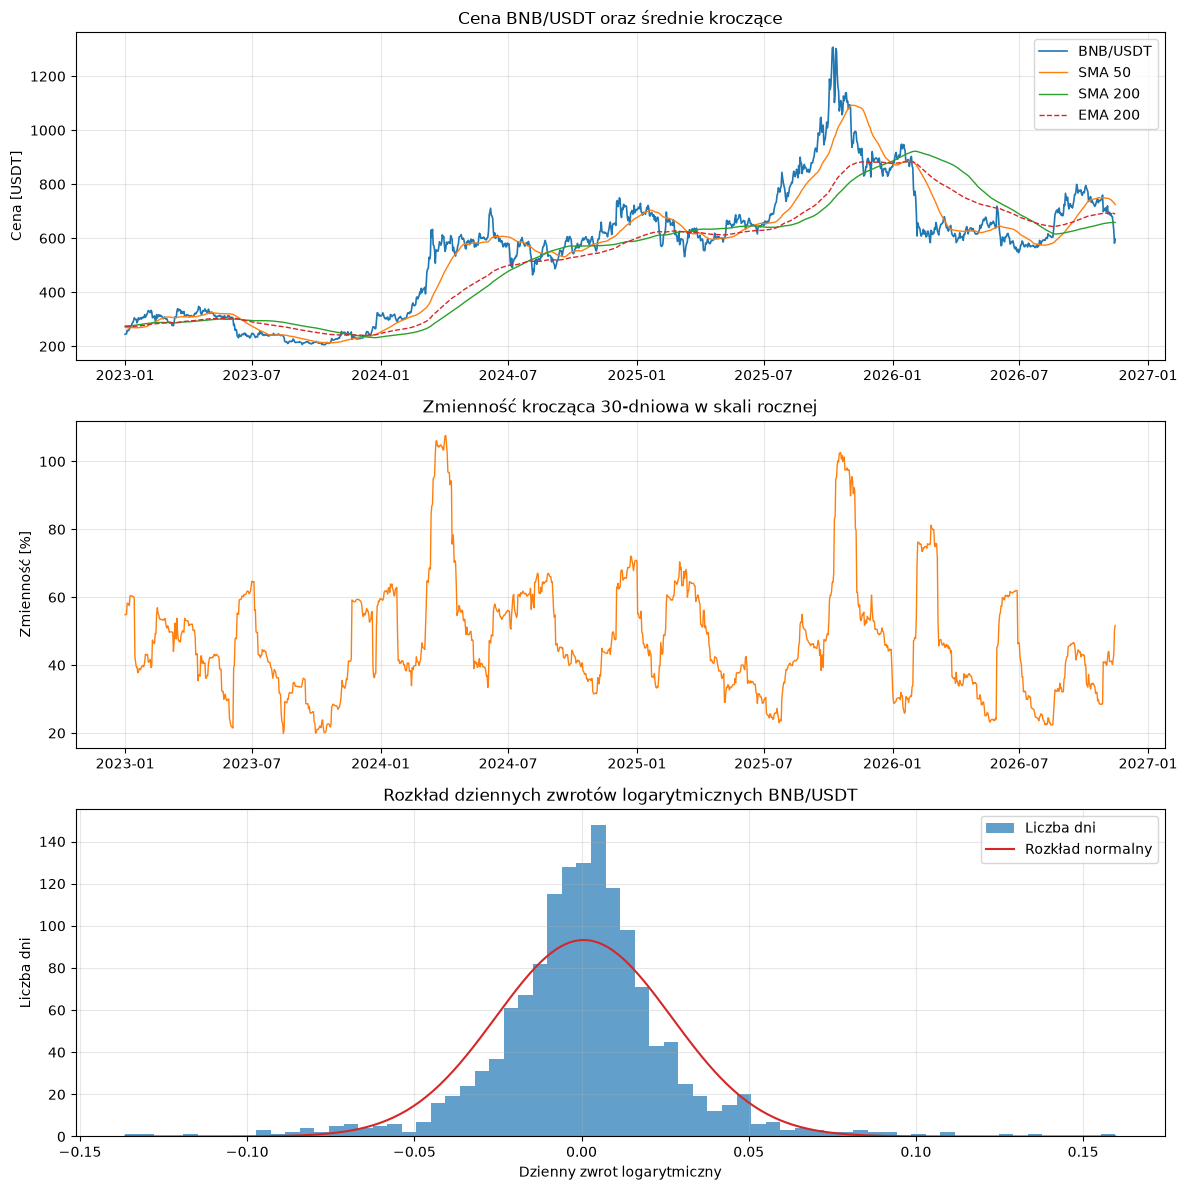

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

axes[0].plot(period_close.index, period_close, label="BNB/USDT", linewidth=1.2)
for label, series in (("SMA 50", sma[50]), ("SMA 200", sma[200]), ("EMA 200", ema_series[200])):
    axes[0].plot(series.index, series, label=label, linestyle="--" if label.startswith("EMA") else "-", linewidth=1.0)
axes[0].set_title("Cena BNB/USDT oraz średnie kroczące")
axes[0].set_ylabel("Cena [USDT]")
axes[0].legend()

axes[1].plot(vol30.index, vol30 * 100, color="tab:orange", linewidth=1.0)
axes[1].set_title("Zmienność krocząca 30-dniowa w skali rocznej")
axes[1].set_ylabel("Zmienność [%]")

if len(log_ret) >= 2:
    _, edges, _ = axes[2].hist(log_ret, bins=bins, alpha=0.7, label="Liczba dni")
    std = log_ret.std(ddof=1)
    if std > 0:
        xs = np.linspace(edges[0], edges[-1], 300)
        bin_width = edges[1] - edges[0]
        expected = stats.norm.pdf(xs, log_ret.mean(), std) * len(log_ret) * bin_width
        axes[2].plot(xs, expected, color="tab:red", label="Rozkład normalny")
    axes[2].legend()
axes[2].set_title("Rozkład dziennych zwrotów logarytmicznych BNB/USDT")
axes[2].set_xlabel("Dzienny zwrot logarytmiczny")
axes[2].set_ylabel("Liczba dni")

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()